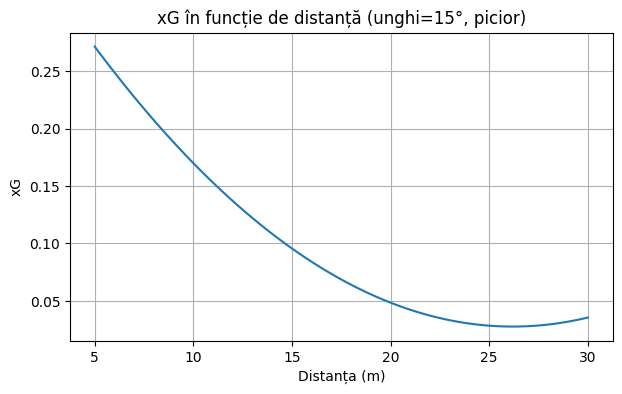

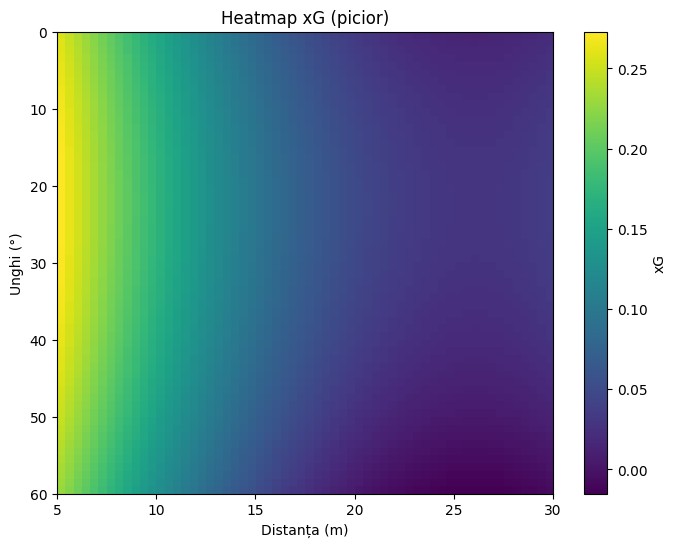

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("../src")

from model import load_data, build_design_matrix, build_target_vector, predict

df = load_data("../data/shots.csv")
df.head()

beta = np.load("../data/beta.npy")
beta

fixed_angle = 15
fixed_body_part = 0

distances = np.linspace(5, 30, 100)
xg_values = [predict(beta, d, fixed_angle, fixed_body_part) for d in distances]

plt.figure(figsize=(7,4))
plt.plot(distances, xg_values)
plt.xlabel("Distanța (m)")
plt.ylabel("xG")
plt.title("xG în funcție de distanță (unghi=15°, picior)")
plt.grid(True)
plt.show()

dist_grid = np.linspace(5, 30, 60)
angle_grid = np.linspace(0, 60, 60)

D, T = np.meshgrid(dist_grid, angle_grid)

body_part = 0  # picior

XG = np.zeros_like(D)

for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        XG[i, j] = predict(beta, D[i, j], T[i, j], body_part)

plt.figure(figsize=(8,6))
hm = plt.imshow(
    XG,
    extent=[dist_grid.min(), dist_grid.max(), angle_grid.max(), angle_grid.min()],
    aspect="auto",
    cmap="viridis"
)
plt.colorbar(hm, label="xG")
plt.xlabel("Distanța (m)")
plt.ylabel("Unghi (°)")
plt.title("Heatmap xG (picior)")
plt.show()